# 06 — p5986 multisensor AE-variance database

This notebook extends the validated waveform layout from Notebook 04 to **12 passive PZT sensors**, establishing a time-series database suitable for Laurenti et al. (2022) LSTM+CNN.

Core principles:

- Each `WF_*.ac` is opened only via memory map; computes the waveform `sum` and `sum of squares` sensor by sensor, without keeping the raw samples of the entire experiment in RAM.
- Window length is estimated solely from training cycles; complete seismic cycles are split chronologically into 63% train, 7% validation, and 30% test.
- Each window only preserves full-window variance; does not use the first/second half subwindows of XGBoost.
- Writes a resumable checkpoint every 25 acoustic files; re-running the high-cost cell will not duplicate already completed files.

Expected inputs: HDF5/CSV from Notebooks 01–03, `acData/run1/WF_*.ac`, settings and sync MAT files.

## Setup & Configuration

In [ ]:
# Google Colab setup
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, json, math, re, time, gc, hashlib, shutil, warnings
import numpy as np
import pandas as pd
import h5py

P5986_ROOT = Path(os.environ.get(
    'P5986_ROOT',
    '/content/drive/MyDrive/MLStressDrop/p5986',
))
AC_DIR = P5986_ROOT / 'acData'
RUN1_DIR = AC_DIR / 'run1'
MAT_DIR = AC_DIR / 'MatFiles'
OUT_DIR = P5986_ROOT / 'colab_outputs_p5986'
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert P5986_ROOT.exists(), (
    f'Cannot find {P5986_ROOT}. Edit P5986_ROOT or add a Drive shortcut.'
)
print('P5986_ROOT =', P5986_ROOT)
print('OUT_DIR    =', OUT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
P5986_ROOT = /content/drive/MyDrive/MLStressDrop/p5986
OUT_DIR    = /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986


In [ ]:
# Configuration — edit here only
WINDOW_FRACTION_OF_TRAIN_MEAN_CYCLE = 0.05
OVERLAP_FRACTION = 0.90
MIN_COVERAGE_FRACTION = 0.75    # 視窗內有效數據的最小涵蓋率，低於此值則捨棄
SENSOR_INDICES = list(range(12))  # 一次處理 12 個 PZT 聲學感測器通道
SPLIT_FRACTIONS = {'train': 0.63, 'validation': 0.07, 'test': 0.30}

# Primary stress target used by Notebook 07. Other modes are still saved.
# 定義主要的預測目標（剪應力）模式
PRIMARY_STRESS_MODE = 'no_drift_correction'
VALID_STRESS_MODES = {
    'no_drift_correction',
    'train_trough_linear_drift',
    'notebook02_full_record',
}
assert PRIMARY_STRESS_MODE in VALID_STRESS_MODES

# Checkpoint 與重跑機制設定
CHECKPOINT_EVERY_FILES = 25
FORCE_RESTART = False
DELETE_CHECKPOINT_AFTER_SUCCESS = False
GITHUB_COMMIT = '6252dcf9a43dae42cb5d1cbf641ba3f6dd4cbb76'

EVENTS_CSV = OUT_DIR / '03_failure_picks_p5986_run1.csv'
LABELS_H5 = OUT_DIR / '03_mechanical_labels_TTF_shear_stress_p5986_run1.h5'
RAW_MECH_H5 = OUT_DIR / '01_mech_raw_p5986_from_binary.h5'
CAL_MECH_H5 = OUT_DIR / '02_mech_calibrated_p5986.h5'
AC_SETTINGS_FILE = MAT_DIR / 'p5986_run1.mat'
SYNC_FILE = AC_DIR / 'p5986_sync_run1.mat'
SYNC_CONVERTED_FILE = AC_DIR / 'p5986_sync_run1_converted.mat' # p5984 left

for required_path in [EVENTS_CSV, LABELS_H5, RAW_MECH_H5, CAL_MECH_H5, AC_SETTINGS_FILE]:
    assert required_path.exists(), required_path


## 1. Load event catalog, define complete-cycle split, and choose window size

`cycle_id=i` represents the complete cycle from failure `i-1` to failure `i`; partial cycles before the first event and after the last event do not enter the supervised database. Windows can cross failures within the same split, but must not cross train/validation/test boundaries.


In [ ]:
# 讀取先前的破裂事件紀錄，依照破裂發生時間排序並重設 index
events = pd.read_csv(EVENTS_CSV).sort_values('failure_time_s').reset_index(drop=True)
failure_times = events['failure_time_s'].to_numpy(np.float64)
assert len(failure_times) >= 10 and np.all(np.diff(failure_times) > 0)

# 定義完整的週期 ID (1 到 N-1) 以及每個週期的持續時間
complete_cycle_ids = np.arange(1, len(failure_times), dtype=np.int64)
complete_cycle_durations = np.diff(failure_times)
n_cycles = len(complete_cycle_ids)

# 根據配置的比例計算 Train 和 Validation 的週期數量 (無條件捨去，確保至少有 1 個)
n_train = max(1, int(np.floor(SPLIT_FRACTIONS['train'] * n_cycles)))
n_validation = max(1, int(np.floor(SPLIT_FRACTIONS['validation'] * n_cycles)))

# 確保留有足夠的週期給 Test set
if n_train + n_validation >= n_cycles:
    raise ValueError('Too few complete cycles for a non-empty test split.')
n_test = n_cycles - n_train - n_validation

# 將週期 ID 劃分至三個子集
cycle_splits = {
    'train': complete_cycle_ids[:n_train],
    'validation': complete_cycle_ids[n_train:n_train + n_validation],
    'test': complete_cycle_ids[n_train + n_validation:],
}

# 根據週期切分，定義 Train/Validation/Test 的絕對時間邊界
split_time_bounds = {
    'train': (failure_times[0], failure_times[n_train]),
    'validation': (failure_times[n_train], failure_times[n_train + n_validation]),
    'test': (failure_times[n_train + n_validation], failure_times[-1]),
}

# 取得訓練集的所有週期長度，並計算平均值與中位數
train_durations = complete_cycle_durations[:n_train]
train_mean_cycle_s = float(np.mean(train_durations))
train_median_cycle_s = float(np.median(train_durations))
# 決定滑動視窗大小：取訓練集平均週期的 5% ，且限制最短不小於 0.005 秒
WINDOW_SECONDS = max(
    0.005,
    round(WINDOW_FRACTION_OF_TRAIN_MEAN_CYCLE * train_mean_cycle_s, 3),
)
# 根據重疊率 (OVERLAP_FRACTION) 計算每次視窗移動的步長 (Step)
STEP_SECONDS = WINDOW_SECONDS * (1.0 - OVERLAP_FRACTION)

# 定義整體分析的起訖時間 (僅包含完整週期)
analysis_start_s = float(failure_times[0])
analysis_end_s = float(failure_times[-1])

# 計算第一個視窗的起點，將其對齊在步長 (STEP_SECONDS) 的整數倍網格上
first_window_start_s = np.ceil(analysis_start_s / STEP_SECONDS) * STEP_SECONDS
last_window_start_s = analysis_end_s - WINDOW_SECONDS

# 生成所有候選視窗的起點陣列。加入 0.5 * STEP_SECONDS 為了防止浮點數精度導致遺漏最後一個點
window_start_s = np.arange(
    first_window_start_s,
    last_window_start_s + 0.5 * STEP_SECONDS,
    STEP_SECONDS,
    dtype=np.float64,
)

# 建立對應的視窗終點與中心點時間陣列
window_end_s = window_start_s + WINDOW_SECONDS
window_center_s = window_start_s + 0.5 * WINDOW_SECONDS

print('complete cycles:', n_cycles)
print({k: len(v) for k, v in cycle_splits.items()})
print('training mean/median cycle:', train_mean_cycle_s, train_median_cycle_s)
print('window / step:', WINDOW_SECONDS, STEP_SECONDS)
print('candidate windows:', len(window_start_s))


complete cycles: 309
{'train': 194, 'validation': 21, 'test': 94}
training mean/median cycle: 2.7465618562296514 2.7420000005583915
window / step: 0.137 0.013699999999999999
candidate windows: 61832


## 2. Load acoustic settings and minimal synchronization variables

The main purpose of this block is to load acoustic hardware settings (Acoustic Settings) and synchronization information (Synchronization), and identify the raw `.ac` files that actually cover our analysis interval.

To prevent out-of-memory (OOM) errors, the loading mechanism extracts only essential keys such as `acTime` (acoustic trigger time) and `ts` (sampling interval) from the 400MB `sync.mat` file, without loading the massive redundant arrays. Next, it intersects the acoustic timestamps with `window_start_s` and `window_end_s` calculated from the previous cell to filter out the list of `WF_*.ac` files (`selected_files`) genuinely required for subsequent variance computation, significantly saving I/O and computational resources.

In [ ]:
import scipy.io as sio

def scalar(x, default=None):
    if x is None:
        return default
    arr = np.asarray(x)
    return arr.reshape(-1)[0] if arr.size else default

def loadmat_any(path):
    try:
        return {k: v for k, v in sio.loadmat(path, squeeze_me=True).items() if not k.startswith('__')}
    except NotImplementedError:
        out = {}
        with h5py.File(path, 'r') as f:
            for key in f.keys():
                out[key] = np.asarray(f[key])
        return out

def text_scalar(x):
    if x is None:
        return None
    if isinstance(x, str):
        return x.strip()
    arr = np.asarray(x)
    if not arr.size:
        return None
    if arr.dtype.kind in {'U', 'S'}:
        return ''.join(arr.astype(str).ravel()).strip()
    return str(arr.ravel()[0]).strip()

def wf_number(path):
    match = re.fullmatch(r'WF_(\d+)\.ac', Path(path).name)
    if match is None:
        raise ValueError(f'Unexpected waveform filename: {path}')
    return int(match.group(1))

def sorted_wf_files(folder):
    return sorted(Path(folder).glob('WF_*.ac'), key=wf_number)

# 讀取聲學硬體設定
settings = loadmat_any(AC_SETTINGS_FILE)
Nsamples = int(scalar(settings.get('Nsamples')))
numAcqs = int(scalar(settings.get('numAcqs')))
numFrames = int(scalar(settings.get('numFrames')))
channels2save = np.asarray(settings['channels2save'], dtype=int).ravel()
numCH = len(channels2save)
samplingFreq_MHz = float(scalar(settings.get('samplingFreq')))
Decimation = int(scalar(settings.get('Decimation'), 1) or 1)
fs_ac_nominal = samplingFreq_MHz * 1e6 / Decimation
numSFpfile = numFrames // 2
numWFpSFpCH = numAcqs
numWFpfilepCH = numSFpfile * numWFpSFpCH
points_per_sf_per_ch = numWFpSFpCH * Nsamples
expected_values_per_file = numSFpfile * numCH * points_per_sf_per_ch
expected_bytes_per_file = expected_values_per_file * np.dtype('<i2').itemsize
assert SENSOR_INDICES == list(range(numCH)), (SENSOR_INDICES, numCH)

# 讀取與驗證同步檔 (Sync File)
wanted_sync_keys = [
    'runname', 'acousticrun', 'totalnumberoffiles',
    'acTime', 'ts', 'ts_adjusted',
]
sync = None
sync_path_used = None
for candidate in [SYNC_FILE, SYNC_CONVERTED_FILE]:
    if not candidate.exists():
        continue
    try:
        candidate_sync = sio.loadmat(
            candidate,
            variable_names=wanted_sync_keys,
            squeeze_me=True,
            struct_as_record=False,
        )
        candidate_sync = {k: v for k, v in candidate_sync.items() if not k.startswith('__')}
        if 'acTime' in candidate_sync and ('ts' in candidate_sync or 'ts_adjusted' in candidate_sync):
            sync, sync_path_used = candidate_sync, candidate
            break
    except NotImplementedError:
        candidate_sync = loadmat_any(candidate)
        if 'acTime' in candidate_sync and ('ts' in candidate_sync or 'ts_adjusted' in candidate_sync):
            sync = {k: candidate_sync[k] for k in wanted_sync_keys if k in candidate_sync}
            sync_path_used = candidate
            break
if sync is None:
    raise RuntimeError('No valid p5986 run1 sync MAT file was loaded.')

assert text_scalar(sync.get('runname')) == 'p5986'
assert text_scalar(sync.get('acousticrun')) == 'run1'
acTime = np.asarray(sync['acTime'], dtype=np.float64).ravel()
assert np.all(np.isfinite(acTime)) and np.all(np.diff(acTime) > 0)

ts_key = 'ts' if 'ts' in sync else 'ts_adjusted'
ts_raw = float(scalar(sync[ts_key]))
nominal_ts = 1.0 / fs_ac_nominal
ts = min([ts_raw, ts_raw * 1e-6], key=lambda v: abs(v - nominal_ts))
if abs(ts - nominal_ts) / nominal_ts > 0.01:
    raise ValueError(f'ts={ts} is inconsistent with nominal {nominal_ts}')

# 對齊檔案與時間軸
sync_nfiles, remainder = divmod(len(acTime), numWFpfilepCH)
assert remainder == 0
wf_files = sorted_wf_files(RUN1_DIR)
assert len(wf_files) == sync_nfiles, (len(wf_files), sync_nfiles)
assert [wf_number(p) for p in wf_files] == list(range(1, sync_nfiles + 1))

# 利用向量化計算，找出每一個 WF_*.ac 檔案的 第一筆 & 最後一筆 波形的索引值
file_first_acq = np.arange(sync_nfiles, dtype=np.int64) * numWFpfilepCH
file_last_acq = file_first_acq + numWFpfilepCH - 1

# 映射出每個檔案在實驗中的絕對 起始/結束 時間 (秒)
file_start_s = acTime[file_first_acq]
file_end_s = acTime[file_last_acq] + (Nsamples - 1) * ts

# 核心篩選：找出時間上與分析目標 (window_start_s 到 window_end_s) 有重疊的聲學檔案
selected_mask = (file_end_s >= window_start_s[0]) & (file_start_s <= window_end_s[-1])
selected_positions = np.flatnonzero(selected_mask)
selected_files = [wf_files[int(i)] for i in selected_positions]
assert selected_files

print('sync:', sync_path_used)
print(dict(Nsamples=Nsamples, numCH=numCH, numSFpfile=numSFpfile,
           waveforms_per_file_per_channel=numWFpfilepCH, ts=ts))
print('selected:', len(selected_files), selected_files[0].name, 'to', selected_files[-1].name)


sync: /content/drive/MyDrive/MLStressDrop/p5986/acData/p5986_sync_run1.mat
{'Nsamples': 512, 'numCH': 12, 'numSFpfile': 10, 'waveforms_per_file_per_channel': 5120, 'ts': 4.000621670105896e-07}
selected: 676 WF_986.ac to WF_1661.ac


## 3. Expensive scan: accumulate all 12 sensor statistics directly into windows

If Colab is interrupted, re-executing this cell will resume from the next file of the Drive checkpoint. Set `FORCE_RESTART=True` only when modifying settings; it will explicitly remove the old checkpoint and recompute.

This cell is the most computationally expensive and core data processing block in the entire notebook.
Its main purpose is to iterate through all filtered acoustic files (`.ac`) and directly accumulate the data statistics of the 12 sensors (including sample count n, sum, and sum of squares) into the corresponding time windows (Windows).

In [ ]:
# 建立一個包含當前所有核心設定的字典，用於生成 Hash 驗證碼
config_payload = {
    'window_seconds': WINDOW_SECONDS,
    'step_seconds': STEP_SECONDS,
    'window_start_first': float(window_start_s[0]),
    'window_start_last': float(window_start_s[-1]),
    'sensor_indices': SENSOR_INDICES,
    'selected_file_numbers': [wf_number(p) for p in selected_files],
    'Nsamples': Nsamples,
    'numCH': numCH,
    'ts': ts,
}
config_hash = hashlib.sha256(
    json.dumps(config_payload, sort_keys=True).encode('utf-8')
).hexdigest()
CHECKPOINT_PATH = OUT_DIR / '06_multisensor_variance_scan_checkpoint.npz'

if FORCE_RESTART and CHECKPOINT_PATH.exists():
    CHECKPOINT_PATH.unlink()
    print('Removed old checkpoint:', CHECKPOINT_PATH)

n_windows = len(window_start_s)

# Checkpoint 載入與初始化區塊
if CHECKPOINT_PATH.exists():
    checkpoint = np.load(CHECKPOINT_PATH, allow_pickle=False)
    saved_hash = str(checkpoint['config_hash'].item())
    if saved_hash != config_hash:
        raise RuntimeError(
            'Checkpoint configuration differs. Review settings, then set FORCE_RESTART=True once.'
        )
    total_n = checkpoint['total_n'].astype(np.int64, copy=True)
    total_sum = checkpoint['total_sum'].astype(np.float64, copy=True)
    total_sumsq = checkpoint['total_sumsq'].astype(np.float64, copy=True)
    first_file_for_window = checkpoint['first_file_for_window'].astype(np.int32, copy=True)
    last_file_for_window = checkpoint['last_file_for_window'].astype(np.int32, copy=True)
    start_position = int(checkpoint['last_completed_position'].item()) + 1
    print('Resuming at selected-file position', start_position)
else:
    total_n = np.zeros(n_windows, dtype=np.int64)
    total_sum = np.zeros((n_windows, numCH), dtype=np.float64)
    total_sumsq = np.zeros((n_windows, numCH), dtype=np.float64)
    first_file_for_window = np.full(n_windows, -1, dtype=np.int32)
    last_file_for_window = np.full(n_windows, -1, dtype=np.int32)
    start_position = 0

def save_checkpoint(last_completed_position):
    partial = CHECKPOINT_PATH.with_name(CHECKPOINT_PATH.stem + '.partial.npz')
    np.savez_compressed(
        partial,
        config_hash=np.array(config_hash),
        last_completed_position=np.array(last_completed_position, dtype=np.int64),
        total_n=total_n,
        total_sum=total_sum,
        total_sumsq=total_sumsq,
        first_file_for_window=first_file_for_window,
        last_file_for_window=last_file_for_window,
    )
    os.replace(partial, CHECKPOINT_PATH)

# 核心運算迴圈
scan_clock = time.time()
for position in range(start_position, len(selected_files)):
    path = selected_files[position]
    fnum = wf_number(path)
    if path.stat().st_size != expected_bytes_per_file:
        raise ValueError(
            f'{path.name}: {path.stat().st_size} bytes, expected {expected_bytes_per_file}'
        )

    # 找出該檔案對應的全域波形 index 與絕對時間中心點
    first_acq = (fnum - 1) * numWFpfilepCH
    last_acq = first_acq + numWFpfilepCH
    centers = acTime[first_acq:last_acq] + 0.5 * (Nsamples - 1) * ts
    assert len(centers) == numWFpfilepCH and np.all(np.diff(centers) > 0)

    j0 = int(np.searchsorted(window_end_s, centers[0], side='right'))
    j1 = int(np.searchsorted(window_start_s, centers[-1], side='right'))
    if j1 > j0:
        local_window_starts = window_start_s[j0:j1]
        local_window_ends = window_end_s[j0:j1]
        left = np.searchsorted(centers, local_window_starts, side='left')
        right = np.searchsorted(centers, local_window_ends, side='left')
        n_waveforms = right - left
        total_n[j0:j1] += n_waveforms.astype(np.int64) * Nsamples

        nonempty = n_waveforms > 0
        target_rows = np.arange(j0, j1)[nonempty]
        first_file_for_window[target_rows[first_file_for_window[target_rows] < 0]] = fnum
        last_file_for_window[target_rows] = fnum

        raw = np.memmap(
            path,
            dtype='<i2',
            mode='r',
            shape=(numSFpfile, numCH, numWFpSFpCH, Nsamples),
            order='C',
        )

        # 針對每個設定好的通道進行運算
        for sensor in SENSOR_INDICES:
            y = raw[:, sensor, :, :].reshape(-1, Nsamples)
            waveform_sum = np.sum(y, axis=1, dtype=np.int64).astype(np.float64)
            waveform_sumsq = np.einsum(
                'ij,ij->i', y, y, dtype=np.float64, optimize=True
            )
            prefix_sum = np.concatenate(([0.0], np.cumsum(waveform_sum, dtype=np.float64)))
            prefix_sumsq = np.concatenate(([0.0], np.cumsum(waveform_sumsq, dtype=np.float64)))
            total_sum[j0:j1, sensor] += prefix_sum[right] - prefix_sum[left]
            total_sumsq[j0:j1, sensor] += prefix_sumsq[right] - prefix_sumsq[left]
            del y, waveform_sum, waveform_sumsq, prefix_sum, prefix_sumsq
        del raw

    completed = position + 1
    if completed == 1 or completed % 20 == 0 or completed == len(selected_files):
        elapsed = time.time() - scan_clock
        done_this_run = completed - start_position
        seconds_per_file = elapsed / max(done_this_run, 1)
        eta_min = seconds_per_file * (len(selected_files) - completed) / 60
        print(f'processed {completed}/{len(selected_files)} ({path.name}); ETA≈{eta_min:.1f} min')
    if completed % CHECKPOINT_EVERY_FILES == 0 or completed == len(selected_files):
        save_checkpoint(position)
    gc.collect()

assert np.any(total_n > 0)
print('scan complete; checkpoint:', CHECKPOINT_PATH)


Resuming at selected-file position 25
processed 40/676 (WF_1025.ac); ETA≈16.7 min
processed 60/676 (WF_1045.ac); ETA≈17.3 min
processed 80/676 (WF_1065.ac); ETA≈18.1 min
processed 100/676 (WF_1085.ac); ETA≈17.8 min
processed 120/676 (WF_1105.ac); ETA≈17.6 min
processed 140/676 (WF_1125.ac); ETA≈17.1 min
processed 160/676 (WF_1145.ac); ETA≈16.8 min
processed 180/676 (WF_1165.ac); ETA≈16.5 min
processed 200/676 (WF_1185.ac); ETA≈15.6 min
processed 220/676 (WF_1205.ac); ETA≈15.1 min
processed 240/676 (WF_1225.ac); ETA≈14.7 min
processed 260/676 (WF_1245.ac); ETA≈14.1 min
processed 280/676 (WF_1265.ac); ETA≈13.6 min
processed 300/676 (WF_1285.ac); ETA≈12.8 min
processed 320/676 (WF_1305.ac); ETA≈12.0 min
processed 340/676 (WF_1325.ac); ETA≈11.3 min
processed 360/676 (WF_1345.ac); ETA≈10.7 min
processed 380/676 (WF_1365.ac); ETA≈10.0 min
processed 400/676 (WF_1385.ac); ETA≈9.3 min
processed 420/676 (WF_1405.ac); ETA≈8.6 min
processed 440/676 (WF_1425.ac); ETA≈8.0 min
processed 460/676 (WF_1

## 4. Compute variances, three stress-label sensitivities, TTF, cycle IDs, and split labels
This cell is the Feature Alignment & Database Construction block of Notebook 06.
Its main purpose is to convert the acoustic features calculated in the previous step (sum, sum of squares) into formal variance (Variance), and precisely align them along the time axis with the mechanical targets (Time-to-Failure, shear stress).


In [ ]:
# 計算每個視窗的平均值 E[x]
# 變異數 = E[x^2] - (E[x])^2
with np.errstate(divide='ignore', invalid='ignore'):
    ae_mean = total_sum / total_n[:, None]
    ae_variance = np.maximum(total_sumsq / total_n[:, None] - ae_mean ** 2, 0.0)
# 計算每個視窗內的實際樣本涵蓋率
coverage_fraction = total_n * ts / WINDOW_SECONDS

# Mechanical time and Notebook-02 current stress.
with h5py.File(CAL_MECH_H5, 'r') as f:
    mech_time_all = np.asarray(f['time_s'][:], dtype=np.float64)
    stress_full_record = np.asarray(f['shear_stress_mpa'][:], dtype=np.float64)
with h5py.File(RAW_MECH_H5, 'r') as f:
    vert_load_raw = np.asarray(f['Vert LOAD'][:], dtype=np.float64)
assert len(mech_time_all) == len(vert_load_raw) == len(stress_full_record)

# Reconstruct the same calibrated vertical stress before Notebook-02 full-record drift removal.
V_LOAD_CAL = 1.0 / (13.0741863033492 * ((2 ** 24) / 20.0))
V_AREA = 2.0 * 0.007696
stress_no_drift = vert_load_raw * V_LOAD_CAL / V_AREA
IDX_V_LOAD_ZERO = 1_005_000
stress_no_drift -= stress_no_drift[IDX_V_LOAD_ZERO]
stress_no_drift[:IDX_V_LOAD_ZERO] = 0.0
for a, b in [(1_449_086, 1_449_129), (3_147_540, 3_147_611)]:
    stress_no_drift[a:b] = np.linspace(stress_no_drift[a], stress_no_drift[b], b - a)

# Estimate only the drift slope from training-cycle troughs, then extrapolate unchanged.
train_event_ids = np.concatenate(([0], cycle_splits['train']))
trough_rows = events.loc[
    events['event_id'].isin(train_event_ids),
    'trough_global_index',
].dropna().astype(int).to_numpy()
trough_rows = trough_rows[(trough_rows >= 0) & (trough_rows < len(stress_no_drift))]
if len(trough_rows) < 5:
    raise ValueError('Too few training troughs to estimate drift sensitivity.')
drift_slope, drift_intercept = np.polyfit(
    mech_time_all[trough_rows],
    stress_no_drift[trough_rows],
    deg=1,
)
drift_reference_time = split_time_bounds['train'][0]
stress_train_drift = stress_no_drift - drift_slope * (mech_time_all - drift_reference_time)

# 準備三種應力模式供後續對比
stress_sources = {
    'no_drift_correction': stress_no_drift,
    'train_trough_linear_drift': stress_train_drift,
    'notebook02_full_record': stress_full_record,
}

# 找出各聲學視窗起訖時間對應的機械數據 Index
mech_left = np.searchsorted(mech_time_all, window_start_s, side='left')
mech_right = np.searchsorted(mech_time_all, window_end_s, side='left')
mech_n = mech_right - mech_left
stress_window_means = {}

# 計算視窗內的平均剪應力
for mode, values in stress_sources.items():
    prefix = np.concatenate(([0.0], np.cumsum(values, dtype=np.float64)))
    out = np.full(len(window_start_s), np.nan, dtype=np.float64)
    good = mech_n > 0
    out[good] = (prefix[mech_right[good]] - prefix[mech_left[good]]) / mech_n[good]
    stress_window_means[mode] = out

# 計算 TTF (Time-To-Failure)
next_event_id = np.searchsorted(failure_times, window_center_s, side='left').astype(np.int64)
valid_next = next_event_id < len(failure_times)
ttf = np.full(len(window_center_s), np.nan, dtype=np.float64)
ttf[valid_next] = failure_times[next_event_id[valid_next]] - window_center_s[valid_next]
tiny_negative = (ttf < 0) & (ttf > -1e-9)
ttf[tiny_negative] = 0.0

# 根據 window 所屬的 cycle_id 賦予 train/val/test 標籤
split_label = np.full(len(window_center_s), 'discard', dtype=object)
split_safe = np.zeros(len(window_center_s), dtype=bool)
for split_name, ids in cycle_splits.items():
    split_label[np.isin(next_event_id, ids)] = split_name
    lo, hi = split_time_bounds[split_name]
    split_safe |= (
        np.isin(next_event_id, ids)
        & (window_start_s >= lo)
        & (window_end_s <= hi)
    )

base_valid = (
    valid_next
    & split_safe
    & (split_label != 'discard')
    & np.isfinite(ttf)
    & (ttf >= 0)
    & (mech_n > 0)
    & np.isfinite(ae_variance).all(axis=1)
    & (coverage_fraction >= MIN_COVERAGE_FRACTION)
)
for values in stress_window_means.values():
    base_valid &= np.isfinite(values)

# Sensor-specific log epsilon is fitted on training rows only.
training_rows = base_valid & (split_label == 'train')
epsilon_by_sensor = []
log_variance = np.empty_like(ae_variance)
for sensor in SENSOR_INDICES:
    positives = ae_variance[training_rows, sensor]
    positives = positives[np.isfinite(positives) & (positives > 0)]
    epsilon = max(
        float(np.percentile(positives, 0.1)) * 1e-3 if len(positives) else 1e-12,
        1e-12,
    )
    epsilon_by_sensor.append(epsilon)
    log_variance[:, sensor] = np.log10(ae_variance[:, sensor] + epsilon)

# 將所有計算結果整合入最終的 Database (Pandas DataFrame)
database = pd.DataFrame({
    'window_id': np.arange(len(window_start_s), dtype=np.int64),
    'window_start_s': window_start_s,
    'window_center_s': window_center_s,
    'window_end_s': window_end_s,
    'window_seconds': WINDOW_SECONDS,
    'step_seconds': STEP_SECONDS,
    'coverage_fraction': coverage_fraction,
    'n_samples_full_window': total_n,
    'wf_file_first': first_file_for_window,
    'wf_file_last': last_file_for_window,
    'cycle_id': next_event_id,
    'event_id': next_event_id,
    'split': split_label,
    'ttf_to_failure_start_s': ttf,
    'mean_shear_stress_mpa_no_drift_correction': stress_window_means['no_drift_correction'],
    'mean_shear_stress_mpa_train_trough_linear_drift': stress_window_means['train_trough_linear_drift'],
    'mean_shear_stress_mpa_notebook02_full_record': stress_window_means['notebook02_full_record'],
})

# 將指定的基準應力模式設為主要 Target
database['mean_shear_stress_mpa'] = database[
    f'mean_shear_stress_mpa_{PRIMARY_STRESS_MODE}'
]

# 展開 12 通道的變異數與 Log 變異數特徵
for sensor in SENSOR_INDICES:
    database[f'ae_var_sensor_{sensor}'] = ae_variance[:, sensor]
    database[f'log10_ae_var_sensor_{sensor}'] = log_variance[:, sensor]

database = database.loc[base_valid].reset_index(drop=True)
database['window_id'] = np.arange(len(database), dtype=np.int64)
assert set(database['split']) == {'train', 'validation', 'test'}
assert np.all(np.diff(database['window_center_s']) > 0)
assert database.filter(regex=r'^log10_ae_var_sensor_').notna().all().all()

# 顯示計算出的線性斜率與最終資料庫的聚合統計資訊
print('drift slope estimated from training troughs:', drift_slope, 'MPa/s')
print('database shape:', database.shape)
display(database.groupby('split').agg(
    rows=('window_id', 'size'),
    cycles=('cycle_id', 'nunique'),
    time_start=('window_start_s', 'min'),
    time_end=('window_end_s', 'max'),
))


drift slope estimated from training troughs: 3.467549917328828e-05 MPa/s
database shape: (61811, 42)


,rows,cycles,time_start,time_end
split,,,,
test,18649,94,2903.1122,3158.7268
train,38883,194,2311.5188,2844.3392
validation,4279,21,2844.3529,2903.0985


## 5. Save database, metadata, and sensor QC

In [ ]:
PARQUET_NAME = '06_multisensor_variance_database_p5986_run1.parquet'
CSV_NAME = '06_multisensor_variance_database_p5986_run1.csv.gz'
QC_NAME = '06_multisensor_variance_sensor_qc_p5986_run1.csv'
META_NAME = '06_multisensor_variance_metadata_p5986_run1.json'

local_parquet = Path('/content') / PARQUET_NAME
local_csv = Path('/content') / CSV_NAME
local_qc = Path('/content') / QC_NAME

# 將 DataFrame 輸出為 Parquet 格式 (使用 zstd 壓縮，解壓縮極快且壓縮率高)
database.to_parquet(local_parquet, index=False, compression='zstd')
database.to_csv(local_csv, index=False, compression='gzip')

qc_rows = []
for sensor in SENSOR_INDICES:
    for scope in ['train', 'all']:
        frame = database if scope == 'all' else database.loc[database['split'] == 'train']
        raw_values = frame[f'ae_var_sensor_{sensor}'].to_numpy(np.float64)
        log_values = frame[f'log10_ae_var_sensor_{sensor}'].to_numpy(np.float64)
        qc_rows.append({
            'sensor_zero_based': sensor,
            'hardware_channel': int(channels2save[sensor]),
            'scope': scope,
            'n_rows': len(frame),
            'variance_median': float(np.median(raw_values)),
            'variance_p01': float(np.percentile(raw_values, 1)),
            'variance_p99': float(np.percentile(raw_values, 99)),
            'zero_fraction': float(np.mean(raw_values == 0)),
            'log_variance_std': float(np.std(log_values)),
        })
sensor_qc = pd.DataFrame(qc_rows)
sensor_qc.to_csv(local_qc, index=False)

# 構建溯源詮釋資料 (Metadata)
metadata = {
    'experiment': 'p5986',
    'run': 'run1',
    'notebook': '06_p5986_multisensor_variance_database',
    'paper': 'Laurenti et al. (2022), Deep learning for laboratory earthquake prediction and autoregressive forecasting of fault zone stress',
    'github_repository': 'lauralaurenti/DNN-earthquake-prediction-forecasting',
    'github_commit_read': GITHUB_COMMIT,
    'inputs': { # 記錄所有上游輸入檔案的路徑
        'events_csv': str(EVENTS_CSV),
        'labels_h5': str(LABELS_H5),
        'raw_mechanical_h5': str(RAW_MECH_H5),
        'calibrated_mechanical_h5': str(CAL_MECH_H5),
        'settings_mat': str(AC_SETTINGS_FILE),
        'sync_mat': str(sync_path_used),
        'acoustic_folder': str(RUN1_DIR),
    },
    'window': { # 記錄決定 Window length 的參數
        'selection': '5% of mean duration of training complete cycles only',
        'window_fraction': WINDOW_FRACTION_OF_TRAIN_MEAN_CYCLE,
        'window_seconds': WINDOW_SECONDS,
        'step_seconds': STEP_SECONDS,
        'overlap_fraction': OVERLAP_FRACTION,
        'train_mean_cycle_s': train_mean_cycle_s,
        'train_median_cycle_s': train_median_cycle_s,
    },
    'variance': { # 記錄變異數的數學定義與常數
        'definition': 'population variance = E[x^2] - E[x]^2, ddof=0',
        'full_window_only': True,
        'sensor_indices_zero_based': SENSOR_INDICES,
        'hardware_channels': channels2save.tolist(),
        'log10_epsilon_by_sensor_training_only': epsilon_by_sensor,
        'minimum_coverage_fraction': MIN_COVERAGE_FRACTION,
    },
    'split': {  # 記錄訓練/驗證/測試集的切分邏輯與結果
        'method': 'chronological complete seismic cycles; windows crossing split boundaries removed',
        'fractions_requested': SPLIT_FRACTIONS,
        'cycle_ids': {k: [int(x) for x in v] for k, v in cycle_splits.items()},
        'time_bounds_s': {k: [float(x) for x in v] for k, v in split_time_bounds.items()},
        'row_counts': {k: int((database['split'] == k).sum()) for k in cycle_splits},
    },
    'targets': {  # 記錄標籤的定義模式
        'ttf': 'window center to next Notebook-03 refined shear-stress peak',
        'shear_stress': 'mean mechanical shear stress over the identical acoustic window',
        'primary_stress_mode': PRIMARY_STRESS_MODE,
        'saved_sensitivity_modes': sorted(VALID_STRESS_MODES),
        'train_trough_drift_slope_mpa_per_s': float(drift_slope),
        'warning': 'Notebook-03 failure picks were derived from Notebook-02 current full-record-corrected stress.',
    },
    'scan': {   # 記錄掃描過程的檔案狀態與檢查碼
        'selected_file_count': len(selected_files),
        'first_file': selected_files[0].name,
        'last_file': selected_files[-1].name,
        'config_hash': config_hash,
        'checkpoint_path': str(CHECKPOINT_PATH),
    },
    'outputs': [PARQUET_NAME, CSV_NAME, QC_NAME, META_NAME],
}
local_meta = Path('/content') / META_NAME
local_meta.write_text(json.dumps(metadata, indent=2), encoding='utf-8')

for local_path in [local_parquet, local_csv, local_qc, local_meta]:
    destination = OUT_DIR / local_path.name
    shutil.copy2(local_path, destination)
    print('saved:', destination)

if DELETE_CHECKPOINT_AFTER_SUCCESS and CHECKPOINT_PATH.exists():
    CHECKPOINT_PATH.unlink()
    print('deleted completed checkpoint:', CHECKPOINT_PATH)


saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_multisensor_variance_database_p5986_run1.parquet
saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_multisensor_variance_database_p5986_run1.csv.gz
saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_multisensor_variance_sensor_qc_p5986_run1.csv
saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/06_multisensor_variance_metadata_p5986_run1.json


## 6. QC plots and optional numerical comparison with Notebook 04 sensor 9


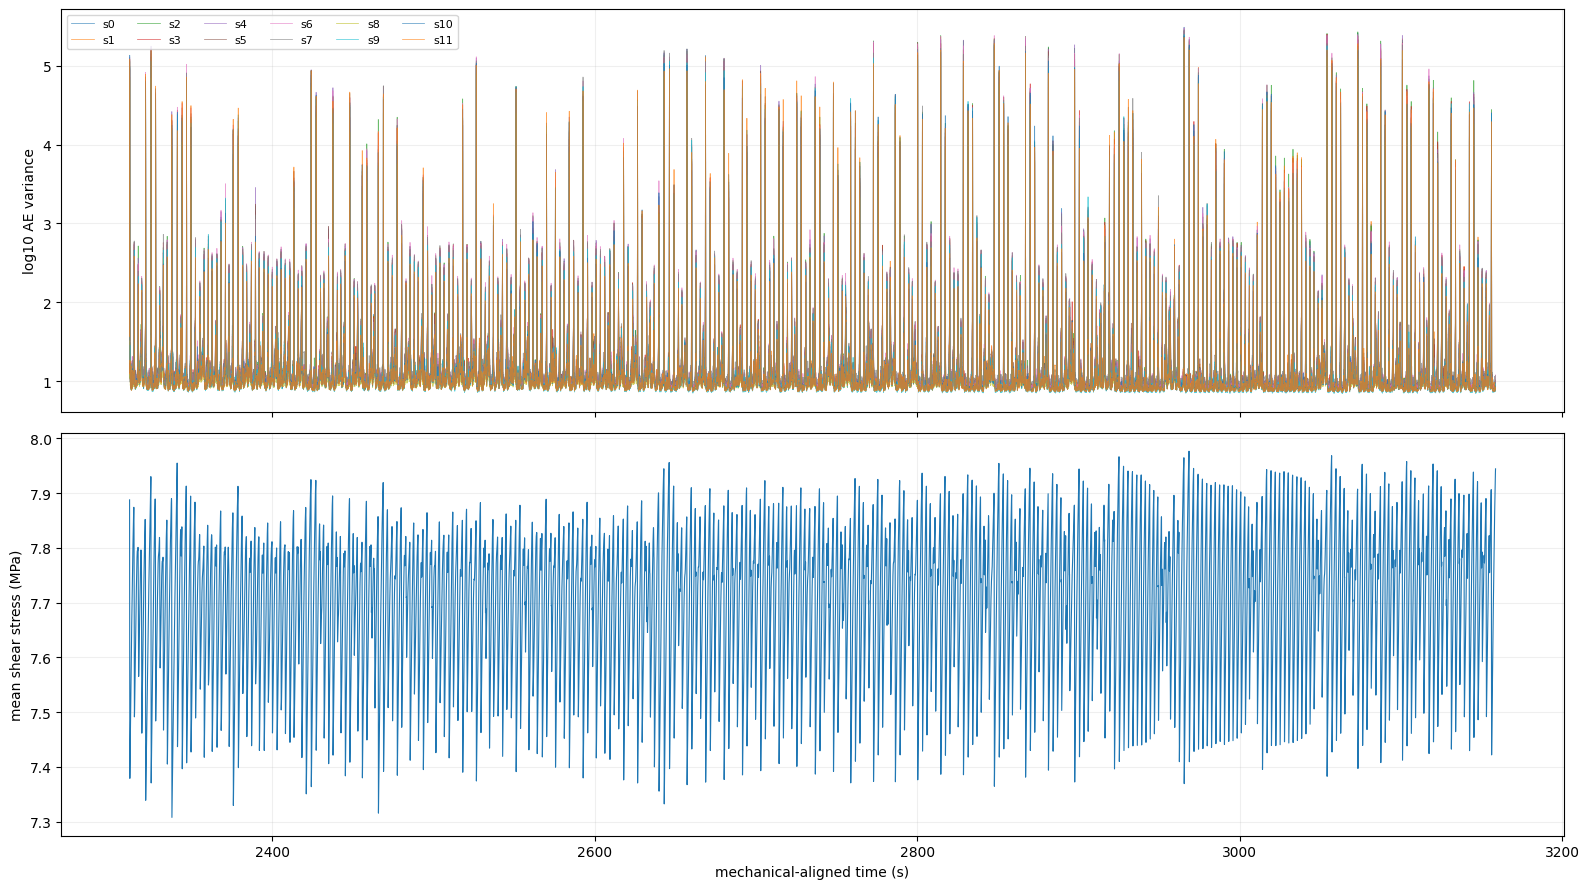

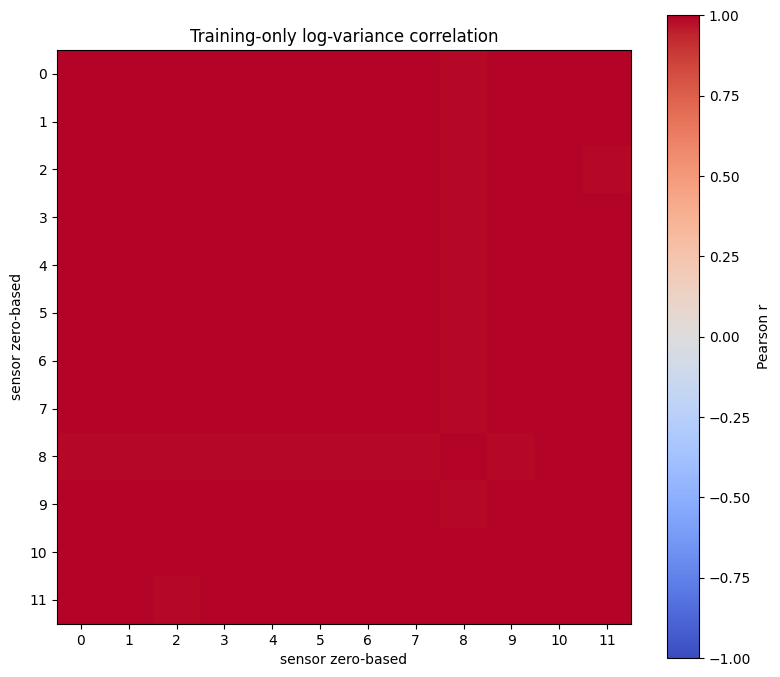

Notebook-04 sensor9 matched rows: 61811
max absolute difference: 5.820766091346741e-11
max relative difference: 3.147127660080327e-16


In [ ]:
import matplotlib.pyplot as plt

# 1. Visualize time series feature & label
# 為了避免圖表過大導致 Colab 崩潰，控制最多只畫 20,000 個點 (降採樣)
plot_frame = database.iloc[::max(1, len(database) // 20_000)].copy()
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

# 上半部：畫出 12 個感測器的 Log10 變異數
for sensor in SENSOR_INDICES:
    axes[0].plot(
        plot_frame['window_center_s'],
        plot_frame[f'log10_ae_var_sensor_{sensor}'],
        lw=0.55,
        alpha=0.7,
        label=f's{sensor}',
    )
axes[0].set_ylabel('log10 AE variance')
axes[0].legend(ncol=6, fontsize=8)
axes[0].grid(alpha=0.2)

# 下半部：畫出對齊好的 Mech mean shear stress
axes[1].plot(plot_frame['window_center_s'], plot_frame['mean_shear_stress_mpa'], lw=0.8)
axes[1].set_ylabel('mean shear stress (MPa)')
axes[1].set_xlabel('mechanical-aligned time (s)')
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()


# 2. 感測器相關性熱力圖
train_logs = database.loc[
    database['split'] == 'train',
    [f'log10_ae_var_sensor_{s}' for s in SENSOR_INDICES],
]
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(train_logs.corr(), vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(numCH), SENSOR_INDICES)
ax.set_yticks(range(numCH), SENSOR_INDICES)
ax.set_xlabel('sensor zero-based')
ax.set_ylabel('sensor zero-based')
ax.set_title('Training-only log-variance correlation')
plt.colorbar(im, ax=ax, label='Pearson r')
plt.tight_layout()
plt.show()

# 3. 數值交叉驗證 (與 Notebook 04 的單通道結果比對)
old_candidates = sorted(OUT_DIR.glob(
    f'04_acoustic_variance_windows_p5986_run1_sensor9_win{WINDOW_SECONDS:g}s_step*_raw.csv.gz'
))
if old_candidates:
    old = pd.read_csv(old_candidates[-1], usecols=['window_center_s', 'ae_var_full_window'])
    new = database[['window_center_s', 'ae_var_sensor_9']].sort_values('window_center_s')
    comparison = pd.merge_asof(
        new,
        old.sort_values('window_center_s'),
        on='window_center_s',
        direction='nearest',
        tolerance=1e-6,
    ).dropna()
    if len(comparison):
        difference = comparison['ae_var_sensor_9'] - comparison['ae_var_full_window']
        relative = np.abs(difference) / np.maximum(np.abs(comparison['ae_var_full_window']), 1.0)
        print('Notebook-04 sensor9 matched rows:', len(comparison))
        print('max absolute difference:', float(np.max(np.abs(difference))))
        print('max relative difference:', float(np.max(relative)))
        assert np.allclose(
            comparison['ae_var_sensor_9'],
            comparison['ae_var_full_window'],
            rtol=1e-8,
            atol=1e-5,
        )
else:
    print('Optional Notebook-04 sensor9 file not found; skipped cross-check.')


## Output contract for Notebook 07

Notebook 07 reads `06_multisensor_variance_database_p5986_run1.parquet` and uses only columns `log10_ae_var_sensor_0` … `log10_ae_var_sensor_11` as neural-network input. Split, targets, stress sensitivity mode, window definition, and sensor hardware mapping are all fixed in metadata.
